# Características visuales aprendidas, Máster en IA (UMU), curso 2026/27


# 🦖 DINOv2: representaciones visuales reutilizables


En el notebook anterior construimos _features_ mediante reglas diseñadas a mano: gradientes, esquinas, SIFT y HOG. Ahora damos el primer salto a las **características aprendidas**. En vez de decidir nosotros qué debe medir cada descriptor, reutilizaremos un modelo preentrenado que transforma una imagen en vectores o _embeddings_.

[DINOv2](https://dinov2.metademolab.com/) es un modelo fundacional visual entrenado de forma autosupervisada (usando millones de ejemplos de la web sin necesidad de ningún tipo de etiquetado manual explícito). Produce una representación global de la imagen y una representación para cada parche. Esas características pueden reutilizarse sin reentrenar el _backbone_ en tareas distintas, como visualización, _matching_, clasificación o estimación de profundidad:

![Diagrama DINOv2](https://github.com/empb/mnti-via-images/blob/main/diagrama_notebook.png?raw=true)

Si tratásemos de establecer una analogía con las _hand-engineered features_ del notebook 06, podría ser la siguiente:

- el token global desempeña un papel parecido al descriptor global HOG;
- los tokens de parche recuerdan a los descriptores locales SIFT, aunque DINOv2 los obtiene sobre una rejilla regular e incorpora contexto global;
- la diferencia esencial es que **SIFT y HOG estaban diseñados manualmente**, mientras que **DINOv2 ha aprendido su representación a partir de millones de datos**.

El objetivo principal de este _notebook_ es, considerando por ahora al modelo como una "caja negra", observar qué información conservan, cómo se comparan y cuáles son sus límites. En el Tema 5 estudiaremos cómo se aprenden características con redes profundas; en el Tema 6 situaremos DINOv2 junto a otros modelos avanzados como DINOv3, CLIP/SigLIP, MAE y SAM. Mientras tanto, podéis encontrar un par de buenas explicaciones previas de cómo se entrenan este tipo de modelos de forma autosupervisada (SSL, de _Self-Supervised-Learning_) [aquí](https://aipapersacademy.com/dinov3/) o [aquí](https://github.com/YarinPerez/DinoV3).


## 0. Preparación del notebook

Este notebook funciona en Jupyter local y en Google Colab. En local necesita el entorno base y el extra `requirements-dinov2.txt`; PyTorch y `torchvision` deben instalarse antes con la variante CPU/CUDA adecuada, siguiendo las instrucciones de `INSTALL.md`.

La primera ejecución necesita conexión a Internet para descargar el conjunto reducido de perros y gatos, el código y los pesos de DINOv2, y el modelo de profundidad. Después se reutilizan las cachés. Se recomienda GPU, pero la configuración predeterminada usa el modelo pequeño y un número reducido de imágenes para que la ruta completa también sea razonable en CPU.


In [1]:
import sys
import time
import urllib.request
from pathlib import Path

try:
    import google.colab  # type: ignore
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import cv2
    import matplotlib.pyplot as plt
    import numpy as np
    import torch
    import torchvision
    import transformers
    from matplotlib.patches import ConnectionPatch, Rectangle
    from PIL import Image
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import ConfusionMatrixDisplay
    from sklearn.metrics.pairwise import cosine_similarity
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from torchvision import transforms
    from transformers import AutoImageProcessor, DPTForDepthEstimation
except ImportError as exc:
    raise ImportError(
        "Faltan dependencias. Consulta la sección DINOv2 de INSTALL.md e instala "
        "PyTorch/torchvision y requirements-dinov2.txt en el kernel activo."
    ) from exc

print("Entorno:", "Google Colab" if IN_COLAB else "Jupyter local")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Transformers:", transformers.__version__)
print("CUDA disponible:", torch.cuda.is_available())


Entorno: Jupyter local
Python: 3.11.11
PyTorch: 2.14.1+cu126 | torchvision: 0.29.1+cu126
Transformers: 5.19.0
CUDA disponible: True


### Datos de ejemplo

Usaremos un subconjunto pequeño de **90 imágenes** (45 perros y 45 gatos) procedentes del conjunto Dogs vs. Cats de Kaggle/Microsoft y alojadas en un [repositorio público](https://github.com/ahatamiz/dog-cat-full-dataset). Es suficiente para ilustrar los experimentos sin obligar a descargar las 25.000 imágenes originales. Separaremos 25 imágenes de cada clase para ajustar el clasificador y 20 distintas para probarlo.

La descarga se guarda bajo `output/07_dinov2/`, tanto al abrir el notebook fuente como al validar su copia mediante `make`. Es idempotente: cada imagen válida se reutiliza en ejecuciones posteriores.


In [2]:
# Al ejecutar la copia dentro de output/, evitamos crear output/output/.
OUTPUT_ROOT = Path("07_dinov2") if Path.cwd().name == "output" else Path("output/07_dinov2")
DATASET_DIR = OUTPUT_ROOT / "cats_dogs_subset"
DOGS_DIR = DATASET_DIR / "dogs"
CATS_DIR = DATASET_DIR / "cats"
DOGS_DIR.mkdir(parents=True, exist_ok=True)
CATS_DIR.mkdir(parents=True, exist_ok=True)

DATA_SOURCE_BASE = (
    "https://raw.githubusercontent.com/ahatamiz/dog-cat-full-dataset/"
    "e295d76547e5c90193064cf41a5fec050bd85833/data/train"
)
# Identificadores comprobados en la revisión concreta del repositorio de origen.
DOG_IDS = (1, 2, 6, 7, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
           21, 22, 23, 26, 27, 28, 29, 31, 32, 33, 35, 37, 39, 41, 43,
           44, 45, 46, 47, 48, 49, 51, 52, 53, 54, 55, 56, 57, 58, 59)
CAT_IDS = (1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 16, 18,
           20, 21, 22, 24, 25, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36,
           37, 38, 39, 41, 42, 43, 44, 46, 47, 50, 51, 52, 53, 54, 55)


def valid_image(path, min_bytes=1000):
    path = Path(path)
    if not path.exists() or path.stat().st_size < min_bytes:
        return False
    try:
        with Image.open(path) as image:
            image.verify()
        return True
    except (OSError, SyntaxError):
        return False


def download_image(category, image_id, destination):
    destination = Path(destination)
    if valid_image(destination):
        return False
    url = f"{DATA_SOURCE_BASE}/{category}/{category[:-1]}.{image_id}.jpg"
    temporary = destination.with_suffix(destination.suffix + ".part")
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=60) as response, temporary.open("wb") as out:
        while chunk := response.read(256 * 1024):
            out.write(chunk)
    if not valid_image(temporary):
        raise RuntimeError(f"Imagen descargada no válida: {url}")
    temporary.replace(destination)
    return True


downloaded = 0
for category, image_ids, folder in [("dogs", DOG_IDS, DOGS_DIR), ("cats", CAT_IDS, CATS_DIR)]:
    singular = category[:-1]
    for image_id in image_ids:
        downloaded += download_image(category, image_id, folder / f"{singular}.{image_id}.jpg")
print(f"Datos listos: {len(DOG_IDS)} perros y {len(CAT_IDS)} gatos; "
      f"{downloaded} imágenes descargadas ahora.")


def image_number(path):
    return int(Path(path).stem.split(".")[-1])


dog_paths = sorted(DOGS_DIR.glob("*.jpg"), key=image_number)
cat_paths = sorted(CATS_DIR.glob("*.jpg"), key=image_number)
if len(dog_paths) != len(DOG_IDS) or len(cat_paths) != len(CAT_IDS):
    raise RuntimeError("El subconjunto no quedó completo; repite la celda para reintentar la descarga.")

train_dog_paths, validation_dog_paths = dog_paths[:25], dog_paths[25:]
train_cat_paths, validation_cat_paths = cat_paths[:25], cat_paths[25:]


Datos listos: 45 perros y 45 gatos; 0 imágenes descargadas ahora.


Antes de comenzar, visualizamos algunos ejemplos. Abrimos las imágenes dentro de un bloque `with` para cerrar sus archivos inmediatamente y trabajamos después con una copia RGB en memoria.


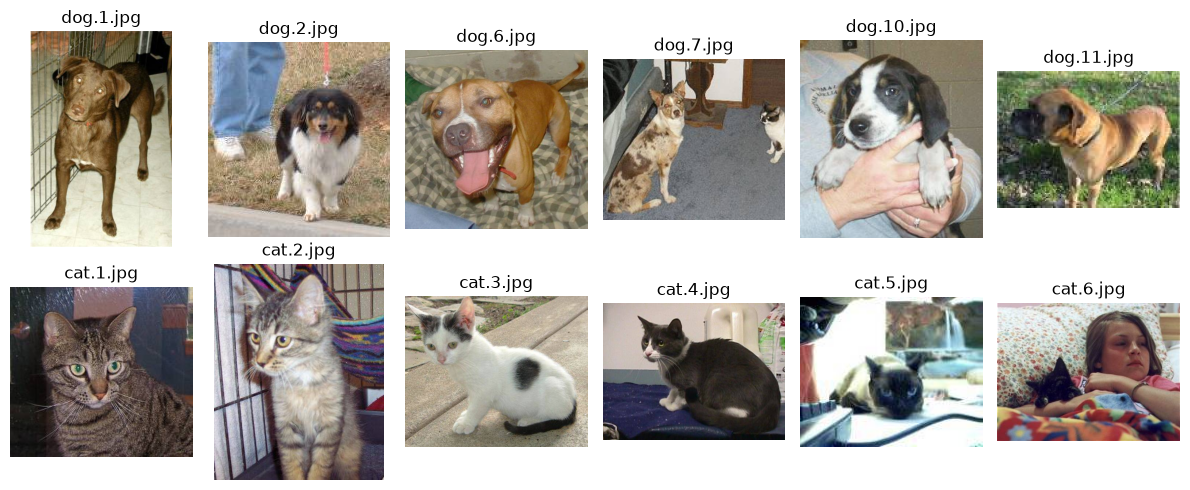

In [3]:
num_images = 6
fig, axes = plt.subplots(2, num_images, figsize=(12, 5))
for row, paths in enumerate([train_dog_paths, train_cat_paths]):
    for ax, path in zip(axes[row], paths[:num_images]):
        with Image.open(path) as image_file:
            image = image_file.convert("RGB")
        ax.imshow(image)
        ax.set_title(path.name)
        ax.axis("off")
plt.tight_layout()
plt.show()


## 1. Carga del modelo de DINOv2

Cargaremos un _backbone_ DINOv2 preentrenado mediante el repositorio oficial de PyTorch Hub. Podemos elegir distintos compromisos entre coste y riqueza de la representación:

| Variante | Dimensión del embedding | Parámetros aproximados |
|---|---:|---:|
| `small` | 384 | 21 M |
| `base` | 768 | 86 M |
| `large` | 1024 | 300 M |

Usaremos `small` por defecto: permite estudiar exactamente las mismas ideas con menos memoria y tiempo de CPU. Cambiar el tamaño modifica la dimensión de los vectores, pero no el resto del notebook. En GPU la inferencia será sensiblemente más rápida; el tiempo exacto depende del equipo y del tamaño de la imagen.


In [4]:
MODEL_SIZE = "small"  # "small", "base" o "large"
PATCH_SIZE = 14

model_names = {
    "small": "dinov2_vits14",
    "base": "dinov2_vitb14",
    "large": "dinov2_vitl14",
}
if MODEL_SIZE not in model_names:
    raise ValueError(f"MODEL_SIZE debe ser uno de {tuple(model_names)}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = model_names[MODEL_SIZE]
print(f"Cargando '{model_name}' en '{device}'...")

# Evita consultar la API de GitHub, que puede responder 403 por límite de peticiones.
# El código sigue descargándose del repositorio oficial y después se reutiliza la caché.
dinov2 = torch.hub.load(
    "facebookresearch/dinov2", model_name, trust_repo=True, skip_validation=True
)
dinov2 = dinov2.to(device).eval()
embedding_dim = dinov2.embed_dim
print(f"Modelo listo: embeddings de {embedding_dim} componentes.")


Cargando 'dinov2_vits14' en 'cuda'...


Using cache found in /home/pedroe/.cache/torch/hub/facebookresearch_dinov2_main
/home/pedroe/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/pedroe/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/pedroe/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Modelo listo: embeddings de 384 componentes.


La función siguiente centraliza el preprocesamiento y la inferencia. Ajusta cada dimensión al múltiplo de 14 más cercano, normaliza como en ImageNet y devuelve:

- el **token CLS**, una representación global de la imagen;
- los **tokens de parche**, una representación contextualizada por cada región de 14×14 píxeles.

La rejilla no conserva la resolución original: cada token resume un parche, y su contenido también depende del resto de la imagen por el mecanismo de atención del transformer.


In [5]:
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


@torch.inference_mode()
def infer_dinov2(image, model=dinov2, device=device, patch_size=PATCH_SIZE):
    image = image.convert("RGB")
    width, height = image.size
    new_width = max(patch_size, round(width / patch_size) * patch_size)
    new_height = max(patch_size, round(height / patch_size) * patch_size)
    resized = image.resize((new_width, new_height), resample=Image.Resampling.BICUBIC)

    image_tensor = preprocess(resized).unsqueeze(0).to(device)
    features = model.forward_features(image_tensor)
    cls_token = features["x_norm_clstoken"].squeeze(0).cpu().numpy()
    patch_tokens = features["x_norm_patchtokens"].squeeze(0).cpu().numpy()
    return cls_token, patch_tokens, resized


with Image.open(train_dog_paths[0]) as image_file:
    image = image_file.convert("RGB")
t0 = time.perf_counter()
cls_token, patch_tokens, resized = infer_dinov2(image)
elapsed = time.perf_counter() - t0

width, height = image.size
new_width, new_height = resized.size
grid_width = new_width // PATCH_SIZE
grid_height = new_height // PATCH_SIZE
print(f"Inferencia completada en {elapsed:.3f} s")
print(f"Imagen: {width}×{height} píxeles -> {new_width}×{new_height} píxeles")
print(f"Rejilla: {grid_width}×{grid_height} = {grid_width * grid_height} parches")
print("Token CLS:", cls_token.shape)
print("Tokens de parche:", patch_tokens.shape)
assert patch_tokens.shape == (grid_width * grid_height, embedding_dim)


Inferencia completada en 0.081 s
Imagen: 327×499 píxeles -> 322×504 píxeles
Rejilla: 23×36 = 828 parches
Token CLS: (384,)
Tokens de parche: (828, 384)


## 2. Reducción de características mediante PCA

Cada parche está descrito por un vector de `embedding_dim` componentes (384 con el modelo `small`). Esa dimensionalidad no puede visualizarse directamente. Aplicaremos **análisis de componentes principales (PCA)** para proyectar los tokens a tres componentes y mostrarlos como canales RGB.

El procedimiento es:

1. extraer tokens de parche de varias imágenes;
2. ajustar PCA para encontrar tres direcciones de máxima varianza;
3. proyectar imágenes no usadas para ajustar PCA;
4. representar las tres coordenadas como color.

PCA no descubre clases ni «entiende perros»: es una simple proyección lineal no supervisada. Los colores solo tienen significado relativo dentro del espacio que hemos ajustado.


Tokens para ajustar PCA: (3138, 384) (6 imágenes)
Varianza explicada por las 3 componentes: 21.7%


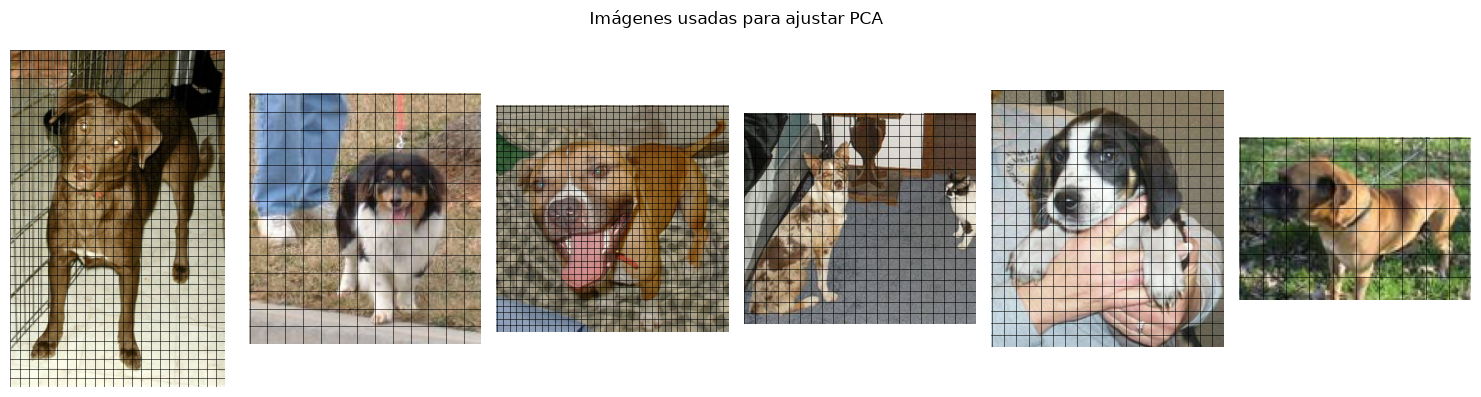

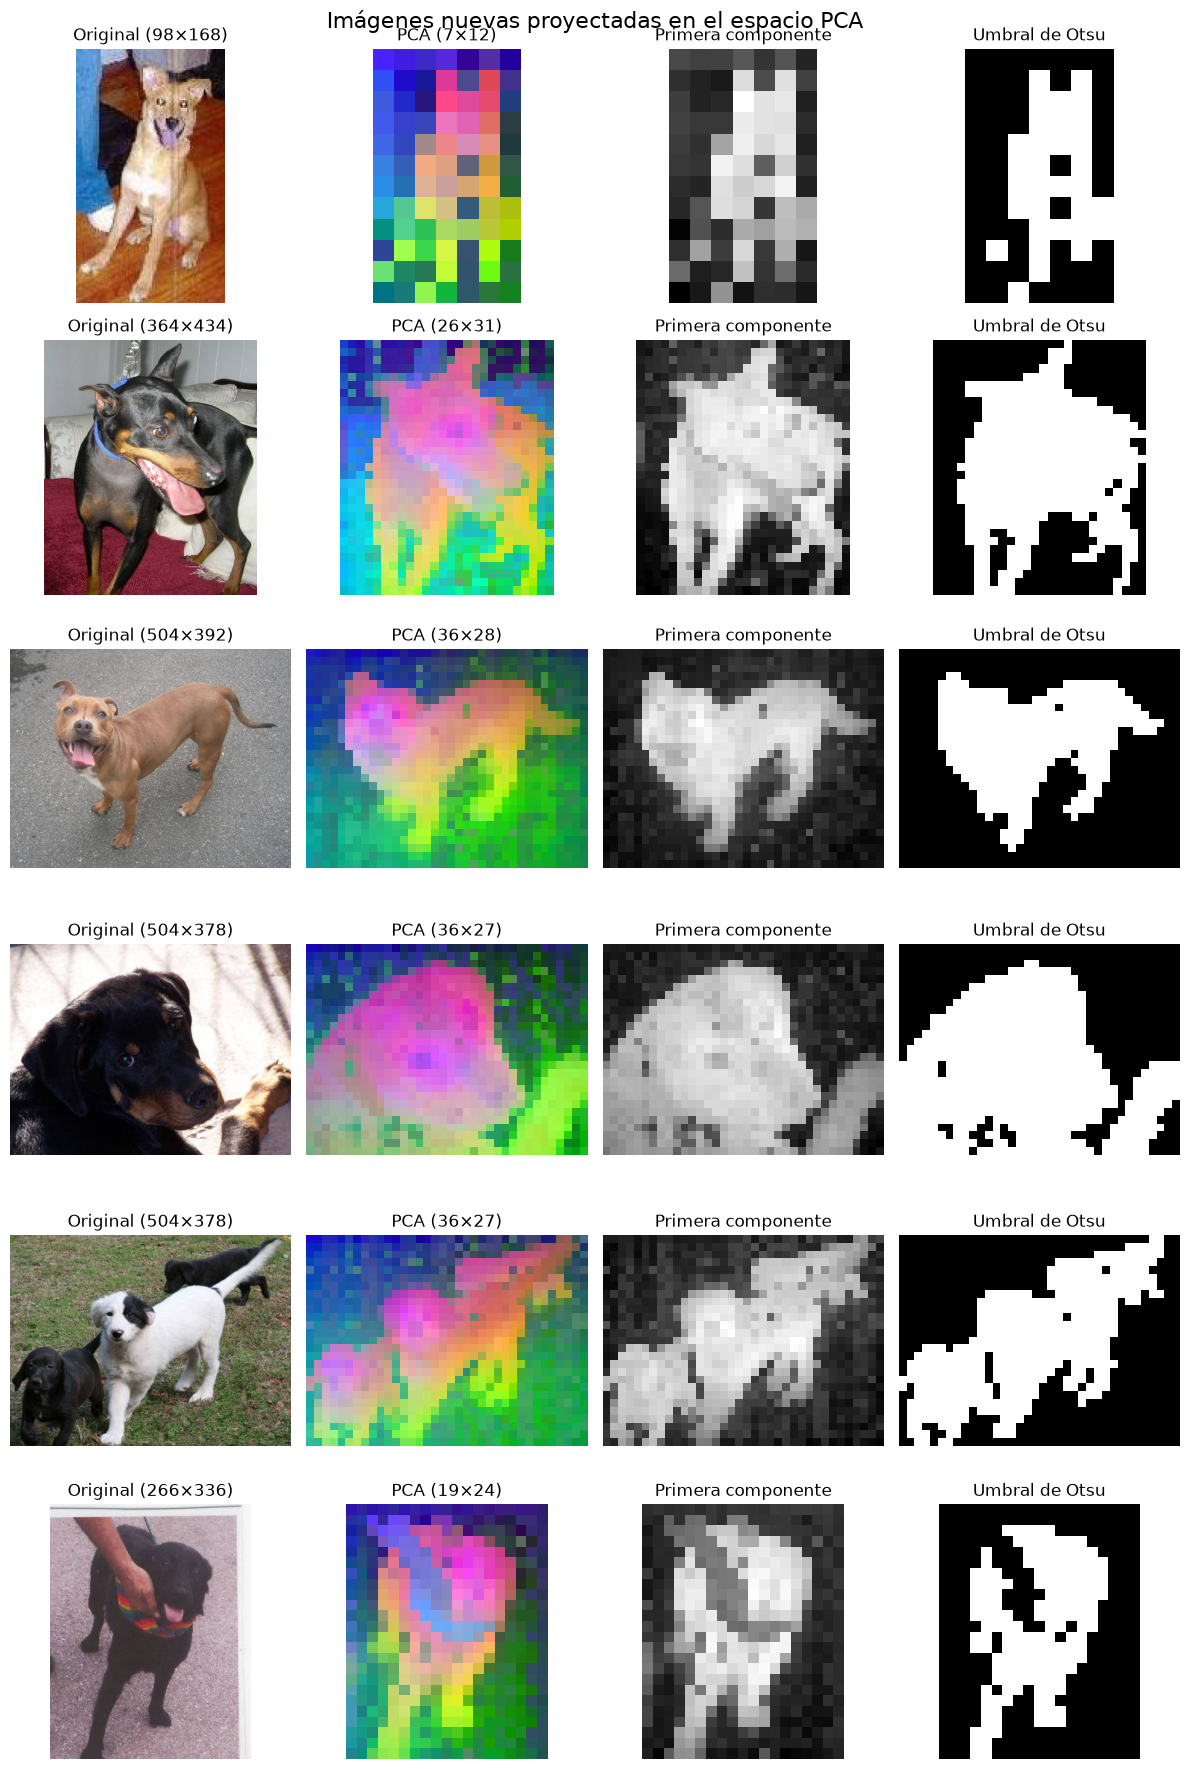

In [6]:
NUM_IMAGES_PCA = 6
first_dogs = []
first_patch_tokens = []
for path in train_dog_paths[:NUM_IMAGES_PCA]:
    with Image.open(path) as image_file:
        image = image_file.convert("RGB")
    _, tokens, resized = infer_dinov2(image)
    first_dogs.append(resized)
    first_patch_tokens.append(tokens)

all_patch_tokens = np.concatenate(first_patch_tokens, axis=0)
print(f"Tokens para ajustar PCA: {all_patch_tokens.shape} ({NUM_IMAGES_PCA} imágenes)")
pca = PCA(n_components=3, random_state=42).fit(all_patch_tokens)
print("Varianza explicada por las 3 componentes:", f"{pca.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(1, len(first_dogs), figsize=(15, 4))
fig.suptitle("Imágenes usadas para ajustar PCA")
for ax, image in zip(axes, first_dogs):
    ax.imshow(image)
    width, height = image.size
    for x in range(0, width, PATCH_SIZE):
        ax.axvline(x=x, color="black", linewidth=0.4)
    for y in range(0, height, PATCH_SIZE):
        ax.axhline(y=y, color="black", linewidth=0.4)
    ax.axis("off")
plt.tight_layout()
plt.show()


def normalize_channels(values):
    minimum = values.min(axis=0, keepdims=True)
    span = np.ptp(values, axis=0, keepdims=True)
    return (values - minimum) / np.maximum(span, np.finfo(np.float32).eps)


NUM_NEW_IMAGES = 6
fig, axes = plt.subplots(NUM_NEW_IMAGES, 4, figsize=(12, 3 * NUM_NEW_IMAGES))
fig.suptitle("Imágenes nuevas proyectadas en el espacio PCA", fontsize=16)
for row, path in enumerate(train_dog_paths[NUM_IMAGES_PCA:NUM_IMAGES_PCA + NUM_NEW_IMAGES]):
    with Image.open(path) as image_file:
        image = image_file.convert("RGB")
    _, tokens, resized = infer_dinov2(image)
    projected = pca.transform(tokens)
    projected_rgb = normalize_channels(projected)

    width, height = resized.size
    grid_width, grid_height = width // PATCH_SIZE, height // PATCH_SIZE
    pca_image = projected_rgb.reshape(grid_height, grid_width, 3)
    first_component = pca_image[:, :, 0]
    _, otsu = cv2.threshold(
        np.round(first_component * 255).astype(np.uint8),
        0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU,
    )

    panels = [resized, pca_image, first_component, otsu]
    titles = [f"Original ({width}×{height})", f"PCA ({grid_width}×{grid_height})",
              "Primera componente", "Umbral de Otsu"]
    for ax, panel, title in zip(axes[row], panels, titles):
        ax.imshow(panel, cmap="gray" if np.asarray(panel).ndim == 2 else None)
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Segmentación mediante similitud de parches

En la visualización PCA anterior, regiones semánticamente relacionadas suelen adquirir colores parecidos. Esto sugiere separar objeto y fondo usando la información de los parches.

Seleccionaremos manualmente en una imagen de referencia una región del perro y otra del fondo. Promediaremos sus _embeddings_ para obtener dos prototipos y asignaremos cada parche de una imagen nueva al prototipo con mayor similitud del coseno.

No estamos entrenando un segmentador completo: damos dos ejemplos espaciales muy simples y clasificamos una rejilla de baja resolución. El resultado dependerá obviamente de las regiones elegidas, del contexto y del tamaño de parche. Pero, con este (extremadamente) simple etiquetado inicial, ya empieza a obtenerse un resultado semánticamente muy plausible: la expresividad semántica de las _features_ aprendidas por DINOv2 empieza a manifestarse, y a resultar útil en escenarios con entrenamiento nulo o prácticamente nulo.


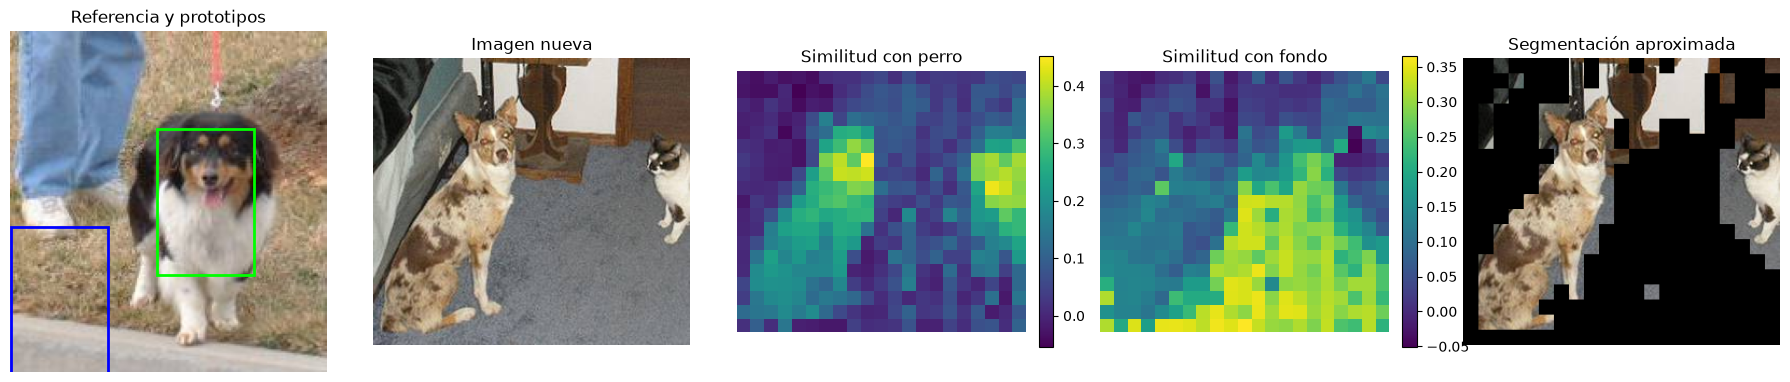

In [7]:
def get_rect_embeddings(image, patch_tokens, rect, patch_size=PATCH_SIZE):
    width, height = image.size
    grid_width, grid_height = width // patch_size, height // patch_size
    dimension = patch_tokens.shape[-1]
    grid = patch_tokens.reshape(grid_height, grid_width, dimension)

    x1, y1, x2, y2 = rect
    px1, py1 = x1 // patch_size, y1 // patch_size
    px2, py2 = int(np.ceil(x2 / patch_size)), int(np.ceil(y2 / patch_size))
    region = grid[py1:py2, px1:px2].reshape(-1, dimension)
    if region.size == 0:
        raise ValueError("El rectángulo no contiene ningún parche.")
    return region


# Imagen de referencia. Las regiones están expresadas sobre la imagen ya redimensionada.
with Image.open(DOGS_DIR / "dog.2.jpg") as image_file:
    image_ref_original = image_file.convert("RGB")
_, tokens_ref, image_ref = infer_dinov2(image_ref_original)
rect_fg = (84, 56, 140, 140)  # perro
rect_bg = (0, 112, 56, 196)   # fondo

# Conservamos toda la representación para medir similitud; PCA se usó solo para visualizar.
embeddings_fg = get_rect_embeddings(image_ref, tokens_ref, rect_fg)
embeddings_bg = get_rect_embeddings(image_ref, tokens_ref, rect_bg)
mean_fg = embeddings_fg.mean(axis=0, keepdims=True)
mean_bg = embeddings_bg.mean(axis=0, keepdims=True)

with Image.open(DOGS_DIR / "dog.7.jpg") as image_file:
    image_new_original = image_file.convert("RGB")
_, tokens_new, image_new = infer_dinov2(image_new_original)
sim_fg = cosine_similarity(tokens_new, mean_fg).ravel()
sim_bg = cosine_similarity(tokens_new, mean_bg).ravel()
labels = sim_fg >= sim_bg

width, height = image_new.size
grid_width, grid_height = width // PATCH_SIZE, height // PATCH_SIZE
sim_fg_grid = sim_fg.reshape(grid_height, grid_width)
sim_bg_grid = sim_bg.reshape(grid_height, grid_width)
labels_grid = labels.reshape(grid_height, grid_width)
mask = cv2.resize(labels_grid.astype(np.uint8), (width, height), interpolation=cv2.INTER_NEAREST)
masked_image = cv2.bitwise_and(np.array(image_new), np.array(image_new), mask=mask)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
axes[0].imshow(image_ref)
axes[0].add_patch(Rectangle(rect_fg[:2], rect_fg[2] - rect_fg[0], rect_fg[3] - rect_fg[1],
                            fill=False, edgecolor="lime", linewidth=2))
axes[0].add_patch(Rectangle(rect_bg[:2], rect_bg[2] - rect_bg[0], rect_bg[3] - rect_bg[1],
                            fill=False, edgecolor="blue", linewidth=2))
axes[0].set_title("Referencia y prototipos")
axes[1].imshow(image_new)
axes[1].set_title("Imagen nueva")
im_fg = axes[2].imshow(sim_fg_grid)
axes[2].set_title("Similitud con perro")
fig.colorbar(im_fg, ax=axes[2], fraction=0.046, pad=0.04)
im_bg = axes[3].imshow(sim_bg_grid)
axes[3].set_title("Similitud con fondo")
fig.colorbar(im_bg, ax=axes[3], fraction=0.046, pad=0.04)
axes[4].imshow(masked_image)
axes[4].set_title("Segmentación aproximada")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 4. _Matching_ entre imágenes


Exploraremos ahora la correspondencia local. Seleccionaremos varios parches en una imagen y, para cada uno, buscaremos en otra imagen el token con mayor similitud del coseno.

A diferencia del _matching_ SIFT del notebook 06, aquí no detectamos puntos de interés ni asignamos orientación o escala a cada región. Tampoco intentaremos estimar una transformación geométrica, como entonces. En este caso, simplemente compararemos posiciones de una rejilla regular con descriptores contextualizados. Tampoco aplicaremos razón entre vecinos, correspondencia mutua ni verificación geométrica, para mantener el ejemplo lo más sencillo posible. Pueden aparecer ciertas correspondencias ambiguas pero, en general, vemos que muchas pueden tener bastante sentido.


Parche  46 -> 254; similitud = 0.387
Parche  71 ->  71; similitud = 0.777
Parche  83 ->  68; similitud = 0.775
Parche 116 -> 117; similitud = 0.783
Parche 181 -> 133; similitud = 0.384
Parche 250 -> 162; similitud = 0.692


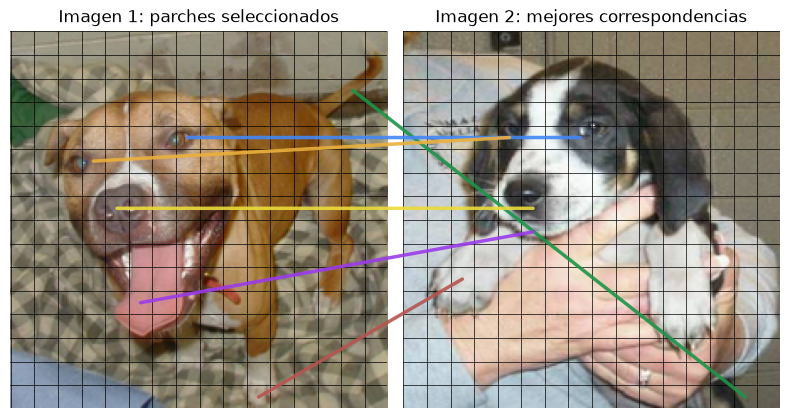

In [8]:
USE_PCA = False
HEIGHT, WIDTH = 224, 224

with Image.open(DOGS_DIR / "dog.6.jpg") as image_file:
    image1 = image_file.convert("RGB").resize((WIDTH, HEIGHT), Image.Resampling.BICUBIC)
with Image.open(DOGS_DIR / "dog.10.jpg") as image_file:
    image2 = image_file.convert("RGB").resize((WIDTH, HEIGHT), Image.Resampling.BICUBIC)
_, patch_tokens1, image1 = infer_dinov2(image1)
_, patch_tokens2, image2 = infer_dinov2(image2)

if USE_PCA:
    patch_tokens1 = pca.transform(patch_tokens1)
    patch_tokens2 = pca.transform(patch_tokens2)

selected_indices = [46, 71, 83, 116, 181, 250]
matches = []
for index1 in selected_indices:
    similarities = cosine_similarity(patch_tokens1[index1:index1 + 1], patch_tokens2).ravel()
    index2 = int(np.argmax(similarities))
    matches.append((index1, index2, float(similarities[index2])))

fig, axes = plt.subplots(1, 2, figsize=(8, 6))
for ax, image, title in zip(axes, [image1, image2],
                            ["Imagen 1: parches seleccionados", "Imagen 2: mejores correspondencias"]):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    for x in range(0, WIDTH, PATCH_SIZE):
        ax.axvline(x=x, color="black", linewidth=0.5)
    for y in range(0, HEIGHT, PATCH_SIZE):
        ax.axhline(y=y, color="black", linewidth=0.5)

colors = ["#1c9448", "#4287f5", "#EBB03B", "#EBDC3B", "#9B3BEB", "#B85450"]
patches_per_row = WIDTH // PATCH_SIZE
for (index1, index2, similarity), color in zip(matches, colors):
    position1 = ((index1 % patches_per_row + 0.5) * PATCH_SIZE,
                 (index1 // patches_per_row + 0.5) * PATCH_SIZE)
    position2 = ((index2 % patches_per_row + 0.5) * PATCH_SIZE,
                 (index2 // patches_per_row + 0.5) * PATCH_SIZE)
    fig.add_artist(ConnectionPatch(
        xyA=position1, coordsA=axes[0].transData,
        xyB=position2, coordsB=axes[1].transData,
        color=color, linewidth=2.5, alpha=0.9,
    ))
    print(f"Parche {index1:3d} -> {index2:3d}; similitud = {similarity:.3f}")
plt.tight_layout()
plt.show()


**Experimento:** cambia `USE_PCA` y compara las correspondencias. Tres componentes bastaban para producir una visualización sugerente, pero suelen perder demasiada información para el _matching_. Esta diferencia ilustra que una proyección útil para visualizar no tiene por qué ser adecuada para otra tarea.


## 5. Clasificación de perros y gatos con un _linear probe_


Entrenaremos un clasificador sencillo sobre los tokens CLS, manteniendo DINOv2 congelado. Esta estrategia se denomina habitualmente **evaluación lineal** o _linear probing_: permite comprobar cuánta información útil para una tarea ya está presente en los _embeddings_ sin ajustar el modelo profundo.

Usaremos deliberadamente pocos ejemplos para que el experimento sea rápido. La prueba ilustra transferencia de representaciones, no pretende obtener una estimación rigurosa del rendimiento: para ello necesitaríamos más datos, varias particiones, métricas adicionales y un análisis de errores.


In [9]:
NUM_TRAIN_DOGS = 25
NUM_TRAIN_CATS = 25
NUM_TEST_DOGS = 20
NUM_TEST_CATS = 20

train_paths = train_dog_paths[:NUM_TRAIN_DOGS] + train_cat_paths[:NUM_TRAIN_CATS]
test_paths = validation_dog_paths[:NUM_TEST_DOGS] + validation_cat_paths[:NUM_TEST_CATS]
y_train = np.array([1] * NUM_TRAIN_DOGS + [0] * NUM_TRAIN_CATS)
y_test = np.array([1] * NUM_TEST_DOGS + [0] * NUM_TEST_CATS)

print(f"Entrenamiento: {len(train_paths)} imágenes")
print(f"Prueba: {len(test_paths)} imágenes de la partición de validación")
assert set(train_paths).isdisjoint(test_paths)


Entrenamiento: 50 imágenes
Prueba: 40 imágenes de la partición de validación


Extraemos un token CLS por imagen, estandarizamos cada componente y ajustamos una regresión logística. DINOv2 permanece en modo evaluación y no recibe gradientes: el único aprendizaje de este apartado ocurre en el clasificador lineal.


Embeddings extraídos en 0.95 s
Matrices: (50, 384) (40, 384)
Exactitud en las 40 imágenes de prueba: 97.5%


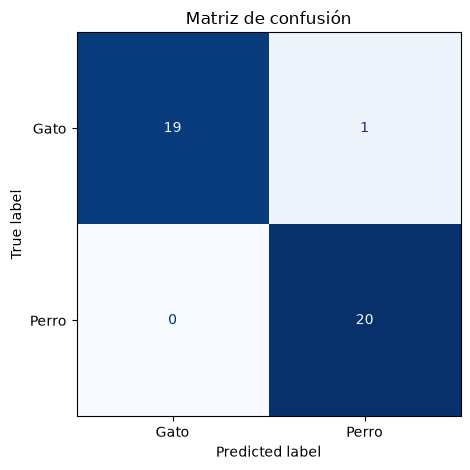

In [10]:
def build_embeddings(paths):
    embeddings = []
    for path in paths:
        with Image.open(path) as image_file:
            image = image_file.convert("RGB")
        cls_embedding, _, _ = infer_dinov2(image)
        embeddings.append(cls_embedding.astype(np.float32))
    return np.stack(embeddings)


t0 = time.perf_counter()
X_train = build_embeddings(train_paths)
X_test = build_embeddings(test_paths)
print(f"Embeddings extraídos en {time.perf_counter() - t0:.2f} s")
print("Matrices:", X_train.shape, X_test.shape)

classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42),
)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
accuracy = classifier.score(X_test, y_test)
print(f"Exactitud en las {len(y_test)} imágenes de prueba: {accuracy:.1%}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Gato", "Perro"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()


Finalmente, inspeccionamos predicciones individuales. Una métrica agregada no explica por qué falla el sistema: conviene mirar los ejemplos erróneos y formular hipótesis sobre pose, fondo, escala, oclusión o ambigüedad visual.


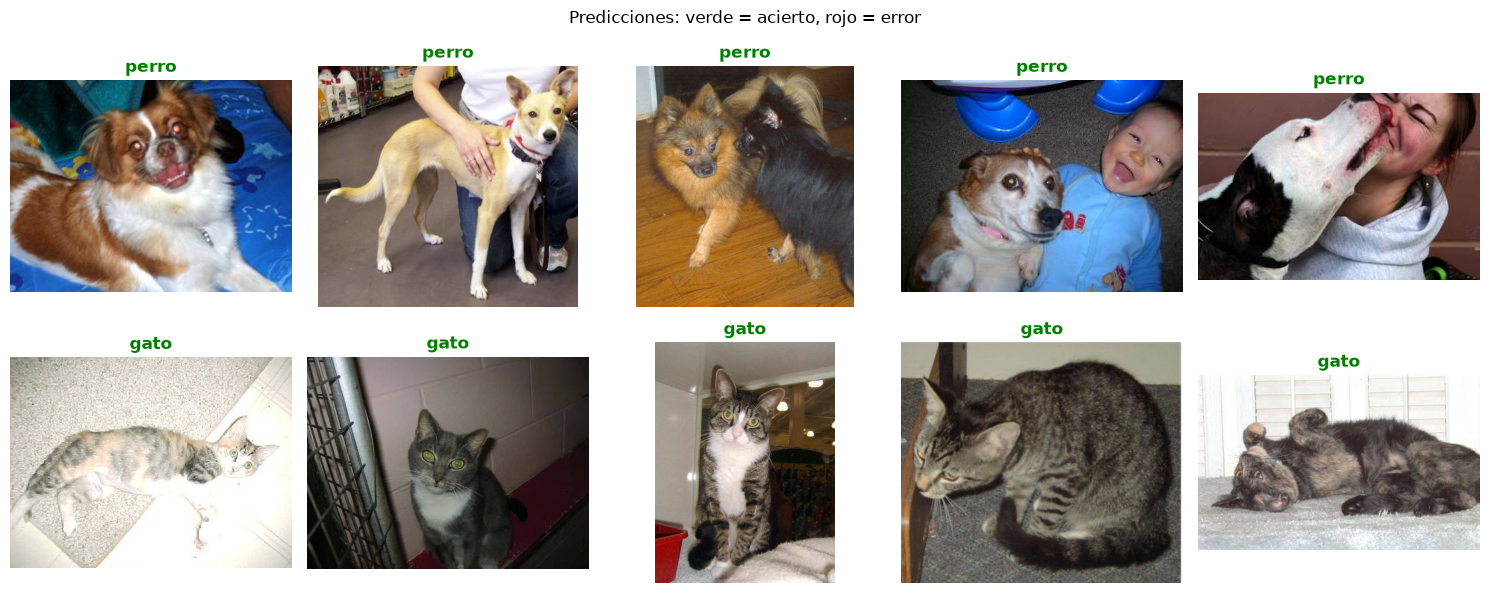

In [11]:
def show_predictions_grid(paths, y_true, y_pred, n_per_class=5, columns=5):
    dog_indices = [i for i, label in enumerate(y_true) if label == 1][:n_per_class]
    cat_indices = [i for i, label in enumerate(y_true) if label == 0][:n_per_class]
    selected = dog_indices + cat_indices
    rows = int(np.ceil(len(selected) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, index in zip(axes, selected):
        with Image.open(paths[index]) as image_file:
            image = image_file.convert("RGB")
        predicted_name = "perro" if y_pred[index] == 1 else "gato"
        color = "green" if y_pred[index] == y_true[index] else "red"
        ax.imshow(image)
        ax.set_title(predicted_name, color=color, fontweight="bold")
        ax.axis("off")
    for ax in axes[len(selected):]:
        ax.set_visible(False)
    fig.suptitle("Predicciones: verde = acierto, rojo = error")
    plt.tight_layout()
    plt.show()


show_predictions_grid(test_paths, y_test, y_pred)


## 6. Un _head_ para estimación monocular de profundidad


Los _embeddings_ de un _backbone_ fundacional pueden alimentar módulos especializados o _heads_. Como ejemplo final cargaremos desde Hugging Face un modelo DPT (Depth Prediction Transformer) que usa DINOv2-base como _backbone_ y ha sido ajustado sobre NYU Depth V2 para estimar profundidad monocular ([enlace](https://huggingface.co/facebook/dpt-dinov2-base-nyu)).

Esto **no significa** que los tokens de salida de DINOv2 contengan directamente una distancia métrica ni que DINOv2 sin ajuste resuelva por sí solo la tarea. El modelo completo combina representaciones de varias capas con un decodificador entrenado para la predicción densa final de, en este caso, la profundidad. Sin embargo, el ejemplo sí que ilustra que las _features_ genéricas de DINOv2 pueden, con postentrenamientos de cabezas mucho más sencillas, y simplemente usando alguna versión "congelada" del modelo DINOv2 como _backbone_, realizar diversas tareas, como segmentación, estimación de profundidad, etc.

El mapa resultante se normaliza solo para visualizarlo y no debe interpretarse como una medida calibrada en metros.


Loading weights:   0%|          | 0/281 [00:00<?, ?it/s]

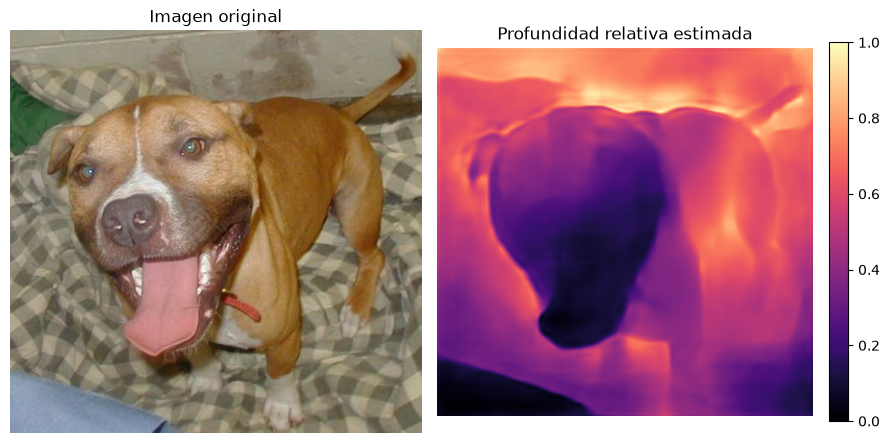

In [12]:
with Image.open(DOGS_DIR / "dog.6.jpg") as image_file:
    depth_image = image_file.convert("RGB")

depth_model_name = "facebook/dpt-dinov2-base-nyu"
image_processor = AutoImageProcessor.from_pretrained(depth_model_name)
depth_model = DPTForDepthEstimation.from_pretrained(depth_model_name).to(device).eval()
inputs = {name: tensor.to(device) for name, tensor in
          image_processor(images=depth_image, return_tensors="pt").items()}

with torch.inference_mode():
    predicted_depth = depth_model(**inputs).predicted_depth
prediction = torch.nn.functional.interpolate(
    predicted_depth.unsqueeze(1),
    size=depth_image.size[::-1],
    mode="bicubic",
    align_corners=False,
).squeeze().cpu().numpy()

depth_range = np.ptp(prediction)
depth = (prediction - prediction.min()) / max(depth_range, np.finfo(np.float32).eps)

fig, axes = plt.subplots(1, 2, figsize=(9, 5))
axes[0].imshow(depth_image)
axes[0].set_title("Imagen original")
depth_plot = axes[1].imshow(depth, cmap="magma")
axes[1].set_title("Profundidad relativa estimada")
fig.colorbar(depth_plot, ax=axes[1], fraction=0.046, pad=0.04)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Liberamos el segundo modelo, especialmente útil si se ejecuta con una GPU pequeña.
del depth_model, inputs, predicted_depth
if device.type == "cuda":
    torch.cuda.empty_cache()


## Ideas principales y enlaces


En este notebook hemos usado una misma representación aprendida en varias escalas y tareas:

- **token CLS** para describir globalmente y clasificar con pocos ejemplos;
- **tokens de parche** para visualizar estructura, segmentar aproximadamente y buscar correspondencias;
- **características intermedias más un _head_ entrenado** para una tarea densa como profundidad.

Los resultados finales dependen del dominio de las imágenes, el preprocesamiento, la resolución, la métrica, los ejemplos elegidos y el módulo de adaptación para cada tarea. DINOv2 es además solo una opción dentro de un panorama que incluye modelos posteriores o alternativos como DINOv3, MAE, CLIP/SigLIP(2) y SAM(2|3), etc.

Referencias:

- [Proyecto y artículo oficial de DINOv2](https://dinov2.metademolab.com/).
- [Repositorio oficial de DINOv2](https://github.com/facebookresearch/dinov2).
- [Modelo DPT-DINOv2 para NYU Depth V2](https://huggingface.co/facebook/dpt-dinov2-base-nyu).
- [Instalación oficial de PyTorch](https://pytorch.org/get-started/locally/).

**Propuestas de exploración:** comparar `small` y `base`; medir qué cambia al usar PCA en el _matching_; repetir la evaluación lineal con varias semillas y tamaños de entrenamiento; analizar de forma razonada casos de fallo del mapa de profundidad.
